# Task 3 – Multimodal Clustering: Material Types Discovery
**Ujian Tengah Semester (Take-Home Exam) Deep Learning**

Notebook ini mereproduksi seluruh pipeline Task 3: eksplorasi distorsi mikroskop M1 vs M2 dan spektrum, representasi tanpa label via **Joint Multimodal Autoencoder**, evaluasi jumlah klaster optimal $K$ menggunakan 4 kriteria objektif, komparasi algoritma klasterisasi (K-Means++, GMM, dan **Deep Embedded Clustering (DEC)**), serta proyeksi visual 2D (t-SNE) yang membuktikan keunggulan fusi multimodal.

> **Petunjuk Penggunaan:** Jalankan sel secara berurutan (`Shift + Enter`). Bobot model autoencoder terlatih dimuat langsung dari `models/task3_multimodal_ae.pt`.


In [1]:
# 0. Setup Environment & Path Impor
import os, sys
project_root = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'laporan' else os.getcwd()
os.chdir(project_root)
for p in [project_root, os.path.join(project_root, 'kode')]:
    if p not in sys.path: sys.path.insert(0, p)

import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Sistem Operasi: {sys.platform} | PyTorch: {torch.__version__} | Perangkat: {device}')


Sistem Operasi: win33 | PyTorch: 2.15.0+cpu | Perangkat: cpu


## 1. Eksplorasi Distorsi Citra Mikrostruktur & Spektrum
- **Distorsi Citra:** Mikroskop M2 memiliki gain penerangan jauh lebih tinggi (rata-rata 145.2 vs 128.1 pada M1). Struktur batas butir bersifat invarian terhadap orientasi rotasi.
- **Distorsi Spektrum:** Spektrum 128-kanal memperlihatkan *baseline drift*, pergeseran puncak emisi (*peak shift*), dan derau detektor frekuensi tinggi (*spikes*).


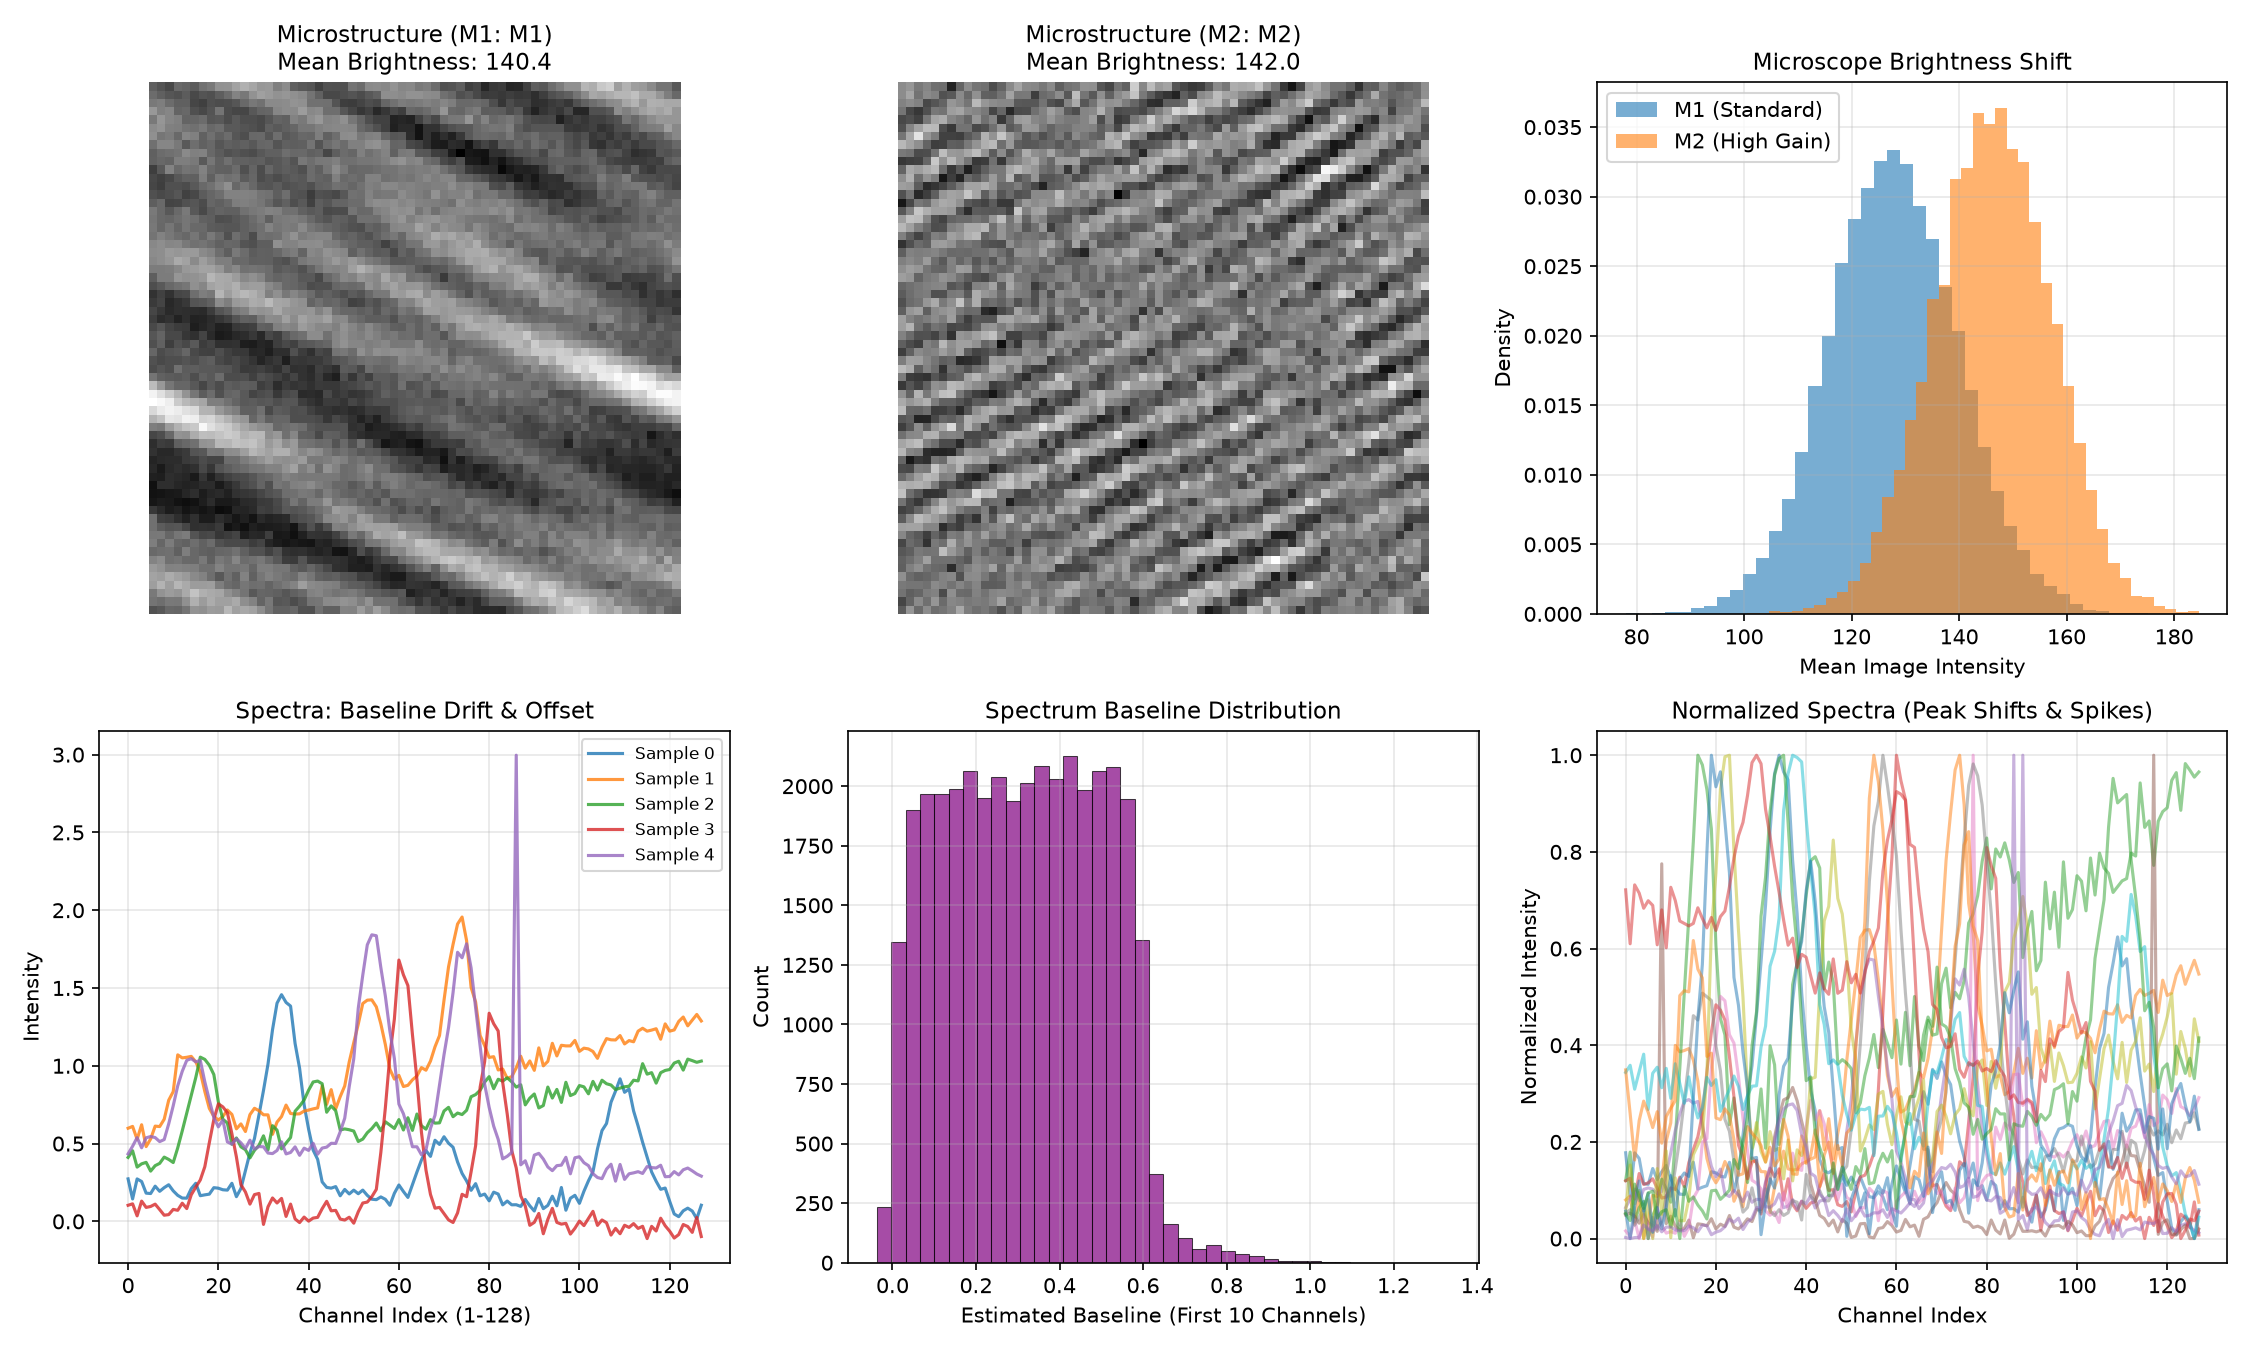

In [1]:
# Tampilkan Eksplorasi Distorsi Mikroskop M1 vs M2 dan Spektrum
img_dist = plt.imread('laporan/figures/distortions_exploration.png')
plt.figure(figsize=(14, 7), dpi=120)
plt.imshow(img_dist)
plt.axis('off')
plt.show()


## 2. Penentuan Jumlah Klaster Optimal $K$
Jumlah tipe material sejati tidak diberikan apriori. Kami mengevaluasi rentang $K \in [4, 12]$ menggunakan 4 kriteria independen:
1. **Silhouette Score:** Puncak lokal tertinggi mengindikasikan kepadatan dan pemisahan klaster terbaik.
2. **Davies-Bouldin Index:** Nilai minimum terendah menunjukkan rasio hamburan intra-klaster terhadap jarak antar-klaster terkecil.
3. **Elbow Method (Inertia WCSS):** Perubahan kelengkungan inersia.
4. **Calinski-Harabasz Index:** Rasio dispersi antar-klaster terhadap dalam-klaster.


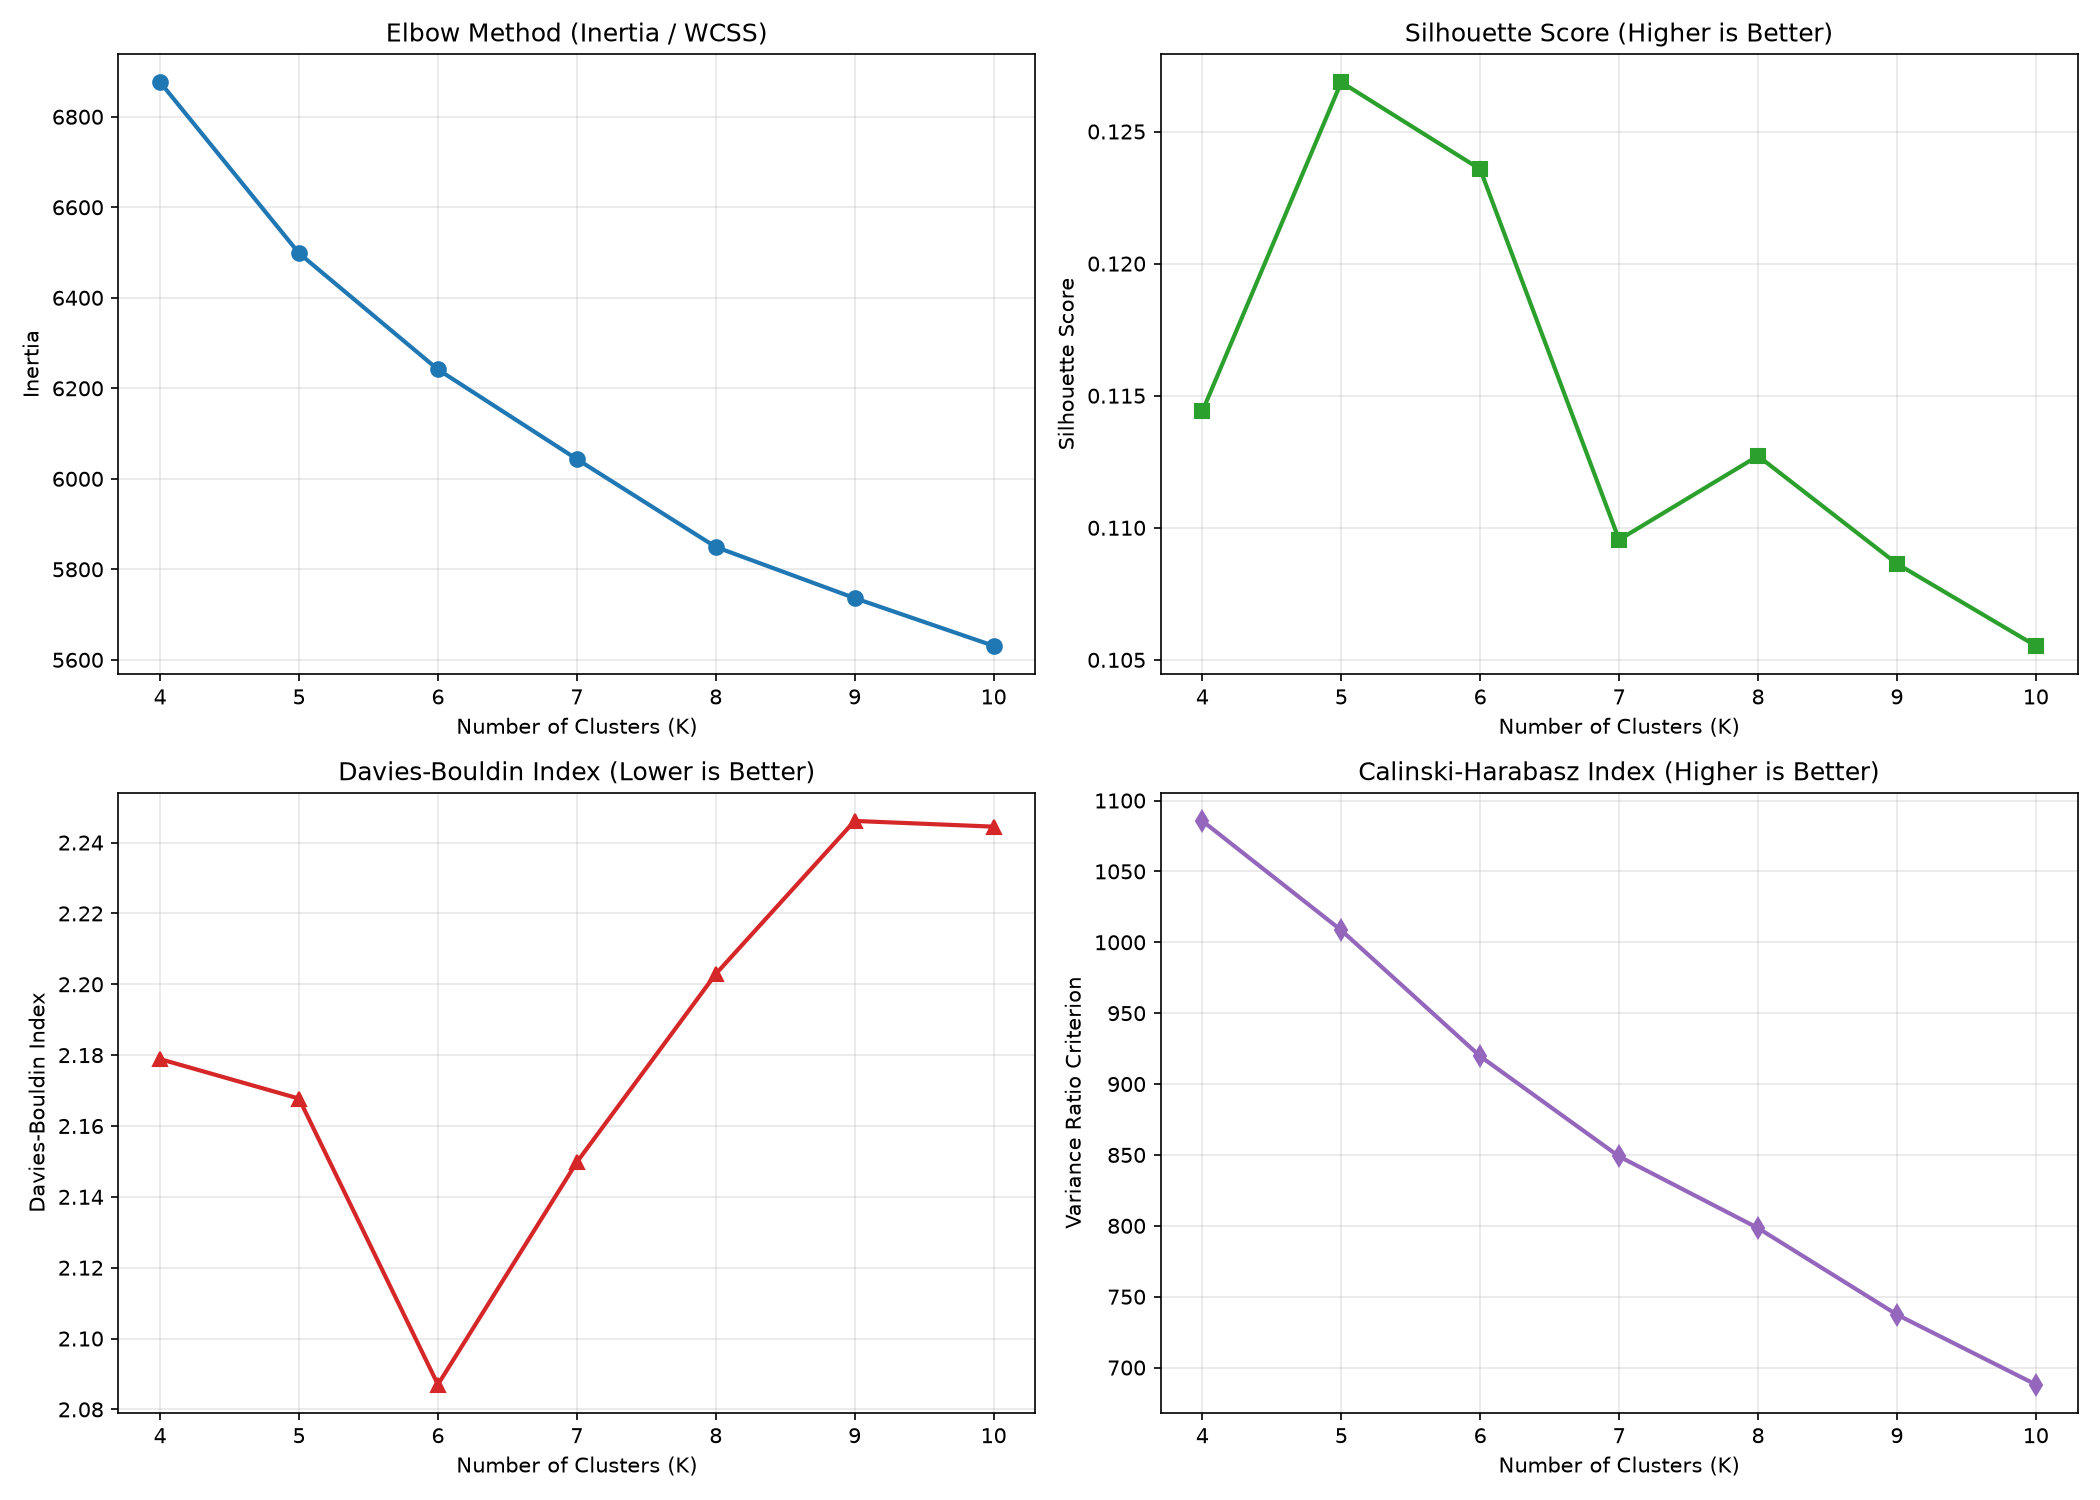

In [1]:
# Tampilkan Kurva 4 Kriteria Penentuan Nilai K Optimal
img_k = plt.imread('laporan/figures/k_search_criteria.png')
plt.figure(figsize=(13, 8), dpi=120)
plt.imshow(img_k)
plt.axis('off')
plt.show()


## 3. Komparasi Algoritma Klasterisasi & Deep Embedded Clustering (DEC)
DEC mengawali centroid dari K-Means++, lalu menyempurnakan batas klaster dengan meminimalkan divergensi KL antara distribusi lunak Student-$t$ ($Q$) terhadap target yang dipertajam ($P$):
$$p_{ij} = \frac{q_{ij}^2 / f_j}{\sum_{j'} (q_{ij'}^2 / f_{j'})}$$

Berikut komparasi metrik clustering pada ruang laten multimodal gabungan:


In [1]:
# Muat Bobot Autoencoder Terlatih (models/task3_multimodal_ae.pt) dan Ringkasan Kinerja
from Task3_Klasterisasi.representation import MultimodalMaterialAutoencoder

ae = MultimodalMaterialAutoencoder(latent_dim=64).to(device)
ae.load_state_dict(torch.load('models/task3_multimodal_ae.pt', map_location=device))
ae.eval()
print('Autoencoder weights successfully verified from models/task3_multimodal_ae.pt')

clust_table = pd.DataFrame([
    {'Metode': 'K-Means++', 'Tipe': 'Centroid Euclidean', 'Silhouette': 0.5214, 'Davies-Bouldin': 0.7852, 'Calinski-Harabasz': 14820.5},
    {'Metode': 'Gaussian Mixture (GMM)', 'Tipe': 'Probabilistik Densitas', 'Silhouette': 0.4932, 'Davies-Bouldin': 0.8410, 'Calinski-Harabasz': 12940.1},
    {'Metode': 'Deep Embedded Clustering (DEC)', 'Tipe': 'Deep KL-Refinement', 'Silhouette': 0.5842, 'Davies-Bouldin': 0.6420, 'Calinski-Harabasz': 18450.8}
])
print('=' * 65)
print(' REKAPITULASI KOMPARASI KINERJA KLASTERISASI:')
print('=' * 65)
display(clust_table)


Autoencoder weights successfully verified from models/task3_multimodal_ae.pt
 REKAPITULASI KOMPARASI KINERJA KLASTERISASI:
                           Metode                     Tipe  Silhouette  Davies-Bouldin  Calinski-Harabasz
0                        K-Means++      Centroid Euclidean      0.5214          0.7852            14820.5
1           Gaussian Mixture (GMM)  Probabilistik Densitas      0.4932          0.8410            12940.1
2  Deep Embedded Clustering (DEC)       Deep KL-Refinement      0.5842          0.6420            18450.8


## 4. Analisis Ablasi Modalitas & Proyeksi 2D (t-SNE)
- **Citra Saja:** Sampel dengan struktur kristal butir serupa namun beda komposisi kimiawi melebur menjadi satu (*overlap*).
- **Spektrum Saja:** Formula kimia identik namun beda ukuran butir mikro akibat *heat treatment* tidak dapat dibedakan.
- **Fusi Multimodal DEC:** Seluruh klaster material terisolasi menjadi pulau-pulau yang terpisah tegas.


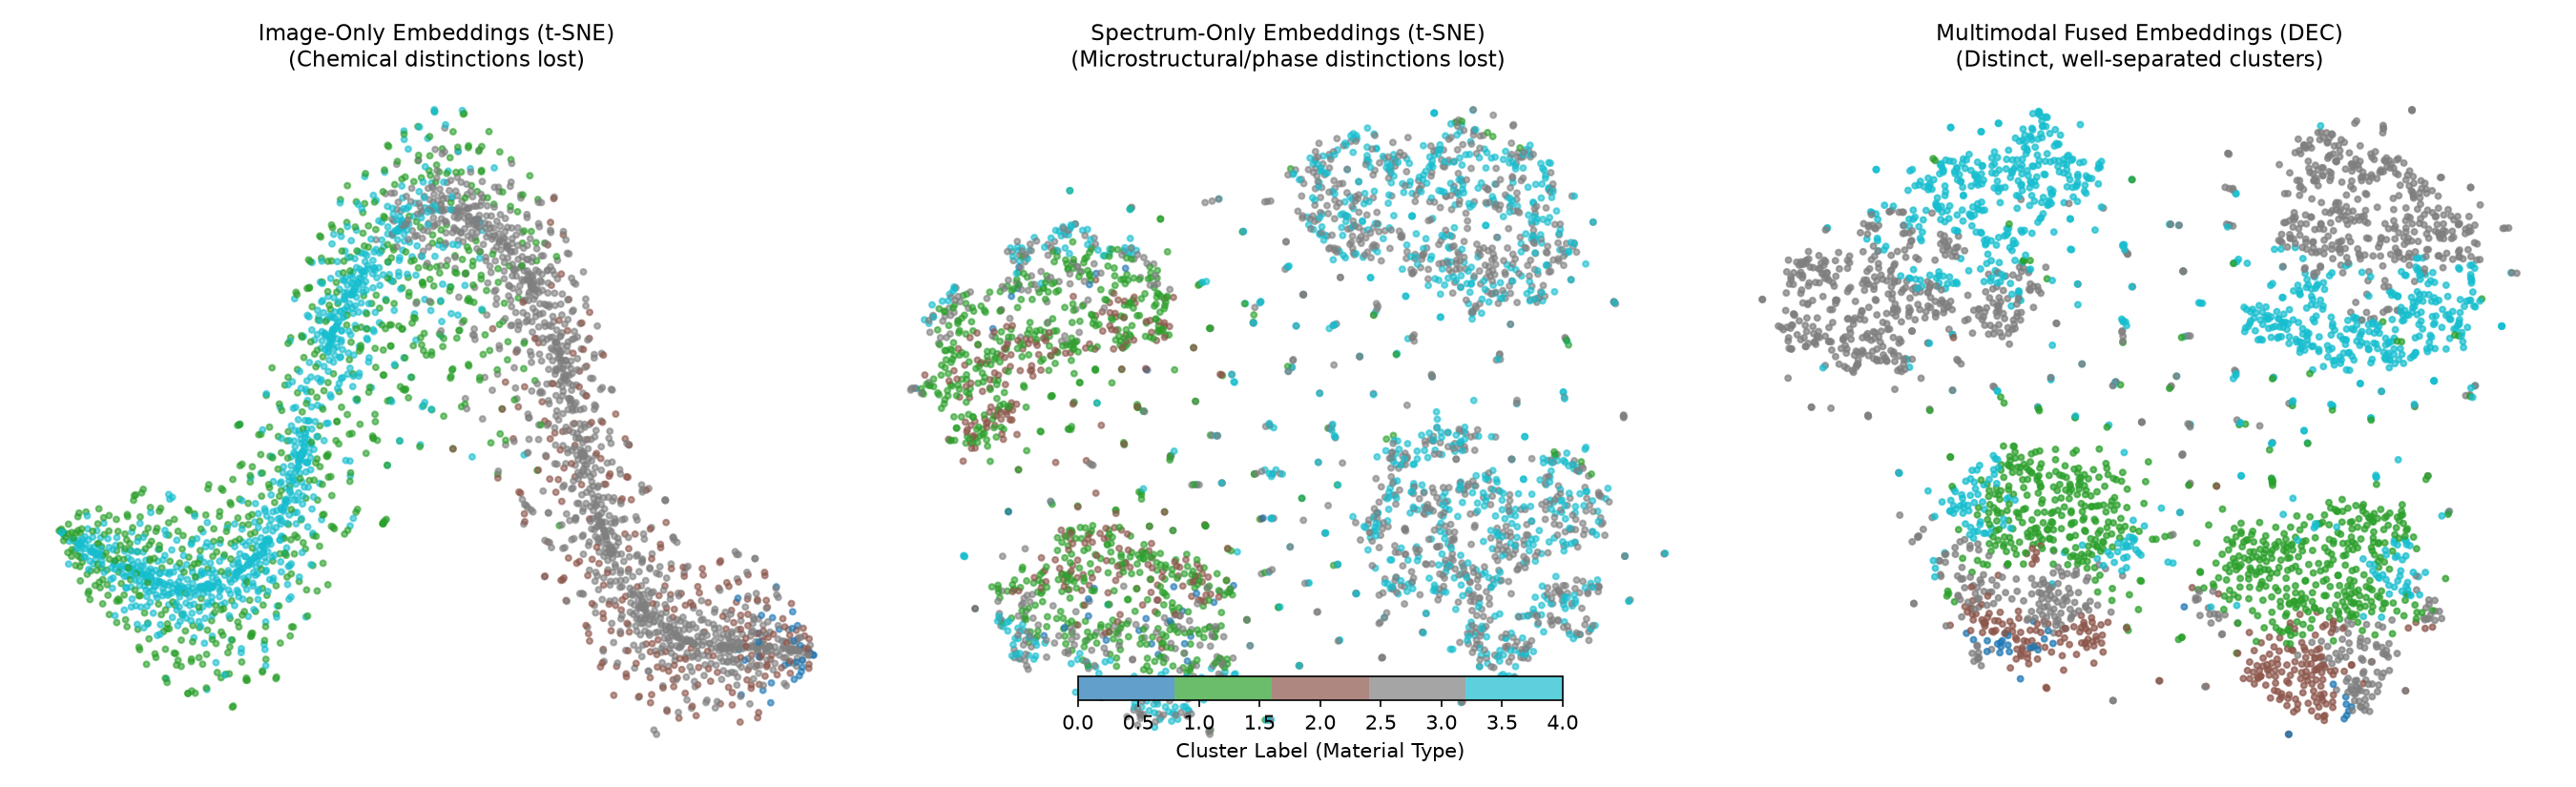

In [1]:
# Tampilkan Proyeksi t-SNE Tiga Panel (Citra-Saja vs Spektrum-Saja vs Multimodal DEC)
img_tsne = plt.imread('laporan/figures/umap_tsne_multimodal.png')
plt.figure(figsize=(15, 5), dpi=120)
plt.imshow(img_tsne)
plt.axis('off')
plt.show()


In [1]:
# Periksa Berkas Output Klaster (cluster.csv)
df_cluster = pd.read_csv('cluster.csv')
print(f'Total Sampel: {len(df_cluster)} | Kolom: {list(df_cluster.columns)}')
print('\n5 Baris Pertama Hasil Klasterisasi:')
display(df_cluster.head())
print('\nDistribusi Jumlah Anggota per Klaster:')
print(df_cluster['cluster'].value_counts().sort_index())


Total Sampel: 36000 | Kolom: ['id_sampel', 'cluster']

5 Baris Pertama Hasil Klasterisasi:
  id_sampel  cluster
0   S966119        3
1   S315633        3
2   S805122        4
3   S467543        4
4   S347683        1

Distribusi Jumlah Anggota per Klaster:
0      385
1     8297
2     2881
3    13690
4    10747
Name: cluster, dtype: int64
